# Semana del 19 de noviembre de 2026 · Galletita con vista 3×3 y obstáculos

El actor de Dreamer junta los datos en el mapa de tres habitaciones con pasillos cortos (`hall5`). Queremos ver si las formas le sirven como referencias para orientarse y llegar a la galleta después de pulsar el botón.

| Condición | Habitaciones laterales |
|---|---|
| `none` | Mapa original |
| `same` | Dos cuadrados verdes |
| `distinct` | Cuadrado verde a la izquierda y triángulo verde a la derecha |

Los obstáculos bloquean las mismas dos casillas en `same` y `distinct`. El agente recibe píxeles RGB. En las tres condiciones se puede llegar a cualquiera de las cuatro esquinas en 23 acciones desde el inicio, pasando por el botón.

## Vista previa

Izquierda de cada fila, mapa completo con la posición inicial. Derecha, imágenes que recibe el agente al situarse frente a la casilla del obstáculo en cada habitación lateral. La galleta aparece después de pulsar el botón azul.

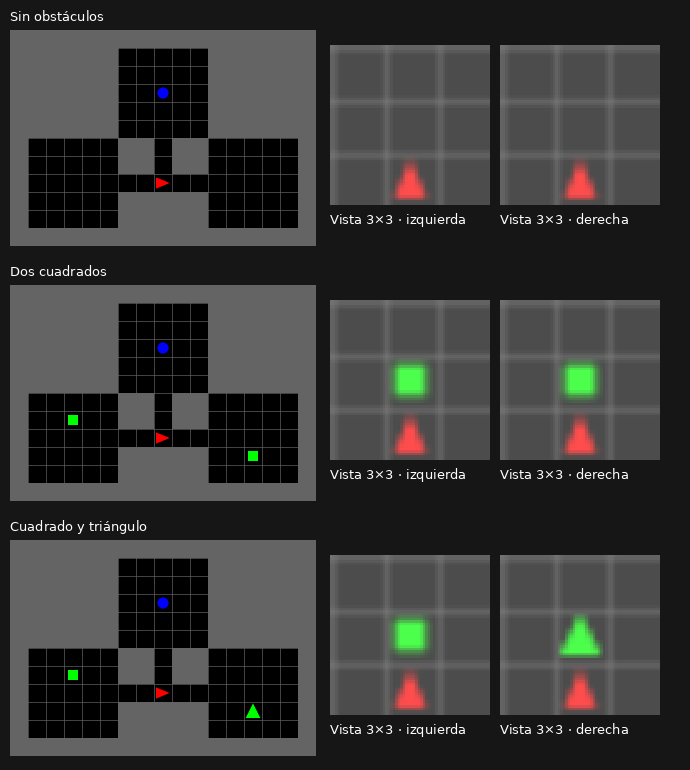

In [1]:
#@title Mostrar la vista previa guardada
from base64 import b64decode
from IPython.display import Image, display

display(Image(data=b64decode("..."), width=690))

## 1. Preparar la GPU y montar Drive

Selecciona una GPU L4 en Colab. Drive conserva los checkpoints, el buffer y las métricas entre sesiones.

In [ ]:
import subprocess
from google.colab import drive

subprocess.run(
    ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
    check=True,
)
drive.mount("/content/drive")

## 2. Preparar el código y comprobar el entorno

Este notebook incluye los cambios de los obstáculos y los aplica sobre una revisión fija del repositorio en una carpeta propia. La celda se puede repetir al volver a la sesión.

In [ ]:
#@title Descargar el código e instalar las dependencias
from pathlib import Path
import subprocess
import sys

REPO = Path("/content/r2dreamer-cookie-semana19")
URL = "https://github.com/FabriRandon/r2dreamer-cookie.git"
REVISION = "0cb0187bf7e6aa764299c36960948a9cd5f36548"
CAMBIOS = 'diff --git a/configs/env/cookie.yaml b/configs/env/cookie.yaml\nindex 1e262b1..d80e598 100644\n--- a/configs/env/cookie.yaml\n+++ b/configs/env/cookie.yaml\n@@ -8,6 +8,8 @@ train_ratio: 512\n time_limit: 2088\n # Only turn and move; moving into the button presses it.\n press_on_move: True\n+# hall5 only: none, same (two squares), or distinct (square and triangle).\n+obstacles: none\n \n seed: ${seed}\n device: ${device}\ndiff --git a/envs/__init__.py b/envs/__init__.py\nindex 766eb8a..266d983 100644\n--- a/envs/__init__.py\n+++ b/envs/__init__.py\n@@ -101,7 +101,13 @@ def make_env(config, id):\n     elif suite == "cookie":\n         import envs.cookie as cookie\n \n-        env = cookie.Cookie(task, config.size, seed=config.seed + id, press_on_move=config.press_on_move)\n+        env = cookie.Cookie(\n+            task,\n+            config.size,\n+            seed=config.seed + id,\n+            press_on_move=config.press_on_move,\n+            obstacles=config.get("obstacles", "none"),\n+        )\n         env = wrappers.OneHotAction(env)\n     elif suite == "metaworld":\n         import envs.metaworld as metaworld\ndiff --git a/envs/cookie.py b/envs/cookie.py\nindex 3b33c58..bcc4bd6 100644\n--- a/envs/cookie.py\n+++ b/envs/cookie.py\n@@ -23,7 +23,7 @@ VARIANTS = {\n \n \n \n-def _shorter_hallways(hallway, fixed_corner=False):\n+def _shorter_hallways(hallway, fixed_corner=False, obstacles="none"):\n     """ThreeRooms with hallways of `hallway` cells instead of 11.\n \n     The three 5x5 rooms stay as they are, and the cookie still appears in an\n@@ -34,13 +34,34 @@ def _shorter_hallways(hallway, fixed_corner=False):\n     """\n     from cookie_env.envs import ThreeRooms\n     from cookie_env.objects import Button\n+    from minigrid.core.constants import COLORS\n     from minigrid.core.grid import Grid\n+    from minigrid.core.world_object import Wall\n+    from minigrid.utils.rendering import fill_coords, point_in_rect, point_in_triangle\n \n     # The hallways meet where the agent starts; the button\'s room sits\n     # `hallway` cells above, and the side rooms as far to each side.\n     cx = cy = hallway + 3\n     corners = [(x, y) for x in (cx - hallway - 2, cx + hallway + 2) for y in (cy - 2, cy + 2)]\n \n+    class Obstacle(Wall):\n+        def __init__(self, triangle):\n+            super().__init__("green")\n+            self.triangle = triangle\n+\n+        def encode(self):\n+            # Grid.render_tile caches by encoding, so each shape needs its own key.\n+            kind, color, _ = super().encode()\n+            return kind, color, int(self.triangle)\n+\n+        def render(self, img):\n+            shape = (\n+                point_in_triangle((0.5, 0.08), (0.9, 0.88), (0.1, 0.88))\n+                if self.triangle\n+                else point_in_rect(0.22, 0.78, 0.22, 0.78)\n+            )\n+            fill_coords(img, shape, COLORS[self.color])\n+\n     class Rooms(ThreeRooms):\n         def _gen_grid(self, width, height):\n             self.grid = Grid(width, height)\n@@ -50,6 +71,9 @@ def _shorter_hallways(hallway, fixed_corner=False):\n             self._generate_hallway(cx - hallway, cy, cx + hallway, cy)\n             self._generate_hallway(cx, cy - hallway, cx, cy)\n             self.put_obj(Button("blue", self.spawn_cookie), cx, cy - hallway)\n+            if obstacles != "none":\n+                self.put_obj(Obstacle(triangle=False), cx - hallway, cy - 1)\n+                self.put_obj(Obstacle(triangle=obstacles == "distinct"), cx + hallway, cy + 1)\n             self.agent_pos = self.agent_start_pos\n             self.agent_dir = self.agent_start_dir\n \n@@ -61,14 +85,15 @@ def _shorter_hallways(hallway, fixed_corner=False):\n \n # Per-step signals the trainer adds up over each episode and logs as\n # episode/<name>, so a run shows progress long before the agent gets cookies:\n-# button presses, distinct cells visited, and steps spent in the button\'s room.\n-LOGS = ("presses", "cells", "button_room")\n+# The two cookie signals count decisions taken with the cookie in view or\n+# directly ahead, where a forward action would collect it.\n+LOGS = ("presses", "cells", "button_room", "cookie_visible", "cookie_in_front")\n \n \n class Cookie(gym.Env):\n     metadata = {}\n \n-    def __init__(self, task, size=(64, 64), seed=0, press_on_move=True):\n+    def __init__(self, task, size=(64, 64), seed=0, press_on_move=True, obstacles="none"):\n         from cookie_env.envs import ThreeRooms\n         from cookie_env.objects import Button\n         from cookie_env.utils import spawner\n@@ -85,12 +110,16 @@ class Cookie(gym.Env):\n         assert view % 2 == 1 and view >= 3, f"the view must be odd and at least 3, got {view}"\n         variant, _, suffix = task.partition("_")\n         assert variant in VARIANTS, (variant, tuple(VARIANTS))\n+        if obstacles not in ("none", "same", "distinct"):\n+            raise ValueError(f"Unknown cookie obstacles mode: {obstacles!r}")\n+        if obstacles != "none" and suffix != "hall5":\n+            raise ValueError("Cookie obstacles require the hall5 layout")\n         options = dict(VARIANTS[variant])\n         full_obs = options.pop("full_obs")\n         rooms = ThreeRooms\n         if suffix.startswith("hall"):\n             fixed_corner = options.pop("spawner", None) == "deterministic_corner"\n-            rooms, layout = _shorter_hallways(int(suffix[len("hall"):]), fixed_corner)\n+            rooms, layout = _shorter_hallways(int(suffix[len("hall"):]), fixed_corner, obstacles)\n             options.update(layout)\n         else:\n             if "spawner" in options:\n@@ -138,7 +167,12 @@ class Cookie(gym.Env):\n \n     def step(self, action):\n         env = self._env.unwrapped\n-        facing_button = isinstance(env.grid.get(*env.front_pos), self._button)\n+        front_pos = tuple(env.front_pos)\n+        facing_button = isinstance(env.grid.get(*front_pos), self._button)\n+        cookie_pos = env.cookie.cur_pos\n+        cookie_in_front = cookie_pos is not None and tuple(cookie_pos) == front_pos\n+        # ThreeRooms renders the entire view patch, including cells behind walls.\n+        cookie_visible = cookie_pos is not None and (self._full_obs or env.in_view(*cookie_pos))\n         if self._press_on_move and action == FORWARD and facing_button:\n             action = TOGGLE\n         obs, reward, terminated, truncated, info = self._env.step(action)\n@@ -151,7 +185,13 @@ class Cookie(gym.Env):\n             "is_first": False,\n             "is_last": done,\n             "is_terminal": terminated,\n-            **self._logs(presses=action == TOGGLE and facing_button, cells=new_cell, button_room=self._in_room(cell)),\n+            **self._logs(\n+                presses=action == TOGGLE and facing_button,\n+                cells=new_cell,\n+                button_room=self._in_room(cell),\n+                cookie_visible=cookie_visible,\n+                cookie_in_front=cookie_in_front,\n+            ),\n         }\n         return obs, np.float32(reward), done, info\n \n@@ -177,7 +217,13 @@ class Cookie(gym.Env):\n             "is_last": False,\n             "is_terminal": False,\n             # The starting cell counts as visited.\n-            **self._logs(presses=False, cells=True, button_room=self._in_room(cell)),\n+            **self._logs(\n+                presses=False,\n+                cells=True,\n+                button_room=self._in_room(cell),\n+                cookie_visible=False,\n+                cookie_in_front=False,\n+            ),\n         }\n \n     def render(self):\n'


def git(*args, **kwargs):
    return subprocess.run(["git", *args], cwd=REPO, **kwargs)

REPO.mkdir(parents=True, exist_ok=True)
if not (REPO / ".git").is_dir():
    git("init", "--quiet", check=True)
actual = git("rev-parse", "--verify", "HEAD", capture_output=True, text=True)
if actual.returncode != 0:
    git("fetch", "--quiet", "--depth=1", URL, REVISION, check=True)
    git("checkout", "--quiet", "--detach", "FETCH_HEAD", check=True)
elif actual.stdout.strip() != REVISION:
    raise RuntimeError(f"Revisión inesperada en {REPO}. Revisa esa copia antes de continuar.")

if git("apply", "--reverse", "--check", "-", input=CAMBIOS, text=True, capture_output=True).returncode:
    git("apply", "--check", "-", input=CAMBIOS, text=True, check=True)
    git("apply", "-", input=CAMBIOS, text=True, check=True)

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "uv"], check=True)
UV = [sys.executable, "-m", "uv"]
PYTHON = REPO / ".venv/bin/python"
if not PYTHON.exists():
    subprocess.run([*UV, "venv", "--python", "3.11", ".venv"], cwd=REPO, check=True)
subprocess.run([*UV, "pip", "install", "--python", str(PYTHON), "-e", ".[cookie]"], cwd=REPO, check=True)

In [ ]:
comprobacion = '''
from envs.cookie import Cookie

for modo in ("none", "same", "distinct"):
    env = Cookie("partial_hall5_view3", obstacles=modo)
    obs = env.reset()
    assert obs["image"].shape == (64, 64, 3)
    assert env._env.unwrapped.agent_view_size == 3
    assert {"log_cookie_visible", "log_cookie_in_front"} <= obs.keys()
    print(f"{modo}: vista 3×3, imagen 64×64, {env._env.unwrapped.max_steps} pasos por partida")
'''
subprocess.run([str(PYTHON), "-c", comprobacion], cwd=REPO, check=True)

## 3. Elegir una condición

Corre las tres condiciones con la misma semilla y los parámetros del experimento 3×3 normal. Para repetir el estudio, cambia la semilla y vuelve a correr las tres. Volver a la misma condición y semilla retoma su checkpoint de Drive.

In [ ]:
MODO = "none" #@param ["none", "same", "distinct"]
SEMILLA = 0 #@param {type:"integer"}
PASOS = 500_000 #@param {type:"integer"}

TAREA = "cookie_partial_hall5_view3"
RAIZ = Path("/content/drive/MyDrive/galleta/semana19/obstaculos3x3")
MODOS = {"none": "Sin obstáculos", "same": "Dos cuadrados", "distinct": "Cuadrado y triángulo"}

def carpeta(modo):
    return RAIZ / f"{modo}_s{SEMILLA}"

assert MODO in MODOS
LOGDIR = carpeta(MODO)
print(MODOS[MODO], "· semilla", SEMILLA)
print(LOGDIR)

def comando(pasos, logdir, *, prueba=False):
    return [
        str(PYTHON), "-u", "train.py",
        "env=cookie", f"env.task={TAREA}", f"env.obstacles={MODO}",
        f"env.steps={pasos}", "env.train_ratio=128", "env.size=[64,64]",
        f"env.eval_episode_num={1 if prueba else 5}", f"seed={SEMILLA}",
        "model.rep_loss=dreamer", "model.plan2explore=False", "trainer.random_policy=False",
        "trainer.eval_every=25000", f"trainer.update_log_every={500 if prueba else 2500}",
        f"trainer.video_pred_log={not prueba}", f"trainer.save_buffer={not prueba}",
        "trainer.save_buffer_every=100000", "buffer.storage_device=cpu",
        f"buffer.max_size={pasos + 1 if prueba else 500_000}", f"logdir={logdir}",
    ]

## 4. Prueba corta opcional

Corre 1.500 pasos en disco local con la condición elegida. Sirve para comprobar el entrenamiento y que se registren las métricas, incluida la pérdida de imagen. La comparación de aprendizaje se hace en la sección siguiente.

In [ ]:
import json
import math
import tempfile

prueba = Path(tempfile.mkdtemp(prefix=f"galleta-3x3-{MODO}-", dir="/content"))
subprocess.run(comando(1500, prueba, prueba=True), cwd=REPO, check=True)
filas = [json.loads(linea) for linea in (prueba / "metrics.jsonl").read_text().splitlines()]
assert any("episode/eval_cookie_in_front" in fila for fila in filas), "Faltan métricas de evaluación"
perdidas = [fila["train/loss/image"] for fila in filas if "train/loss/image" in fila]
assert perdidas and all(math.isfinite(p) for p in perdidas), "Revisa la pérdida de imagen y la GPU"
print("Prueba completada:", prueba)

## 5. Entrenar o retomar

Ejecuta esta celda para la condición seleccionada. La barra muestra los pasos y el tiempo estimado a medida que llegan los reportes de entrenamiento. Para detenerla, pulsa el botón de parar y espera a que termine de guardar en Drive.

In [ ]:
import re
from tqdm.auto import tqdm

paso_log = re.compile(r"^\[(\d+)\]")
paso_reinicio = re.compile(r"^Resuming from .* at step (\d+)")
paso_final = re.compile(r"^Training finished at step (\d+)\.")
args = comando(PASOS, LOGDIR)
proceso = subprocess.Popen(
    args, cwd=REPO, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
    text=True, bufsize=1,
)

barra = tqdm(total=PASOS, desc=MODOS[MODO], unit="paso", smoothing=0)
barra.set_postfix_str("preparando")
detenido = False
try:
    while True:
        try:
            for linea in proceso.stdout:
                reinicio = paso_reinicio.match(linea)
                paso = paso_log.match(linea) or paso_final.match(linea)
                if reinicio:
                    barra.reset(total=PASOS)
                    barra.n = min(int(reinicio[1]), PASOS)
                    barra.initial = barra.last_print_n = barra.n
                    barra.refresh()
                if paso:
                    barra.update(max(0, min(int(paso[1]), PASOS) - barra.n))
                    if " progress " in linea:
                        continue
                if linea.startswith("Evaluating"):
                    barra.set_postfix_str("evaluando")
                elif "Saving the replay buffer" in linea:
                    barra.set_postfix_str("guardando el buffer")
                elif paso:
                    barra.set_postfix_str("")
                tqdm.write(linea.rstrip())
            estado = proceso.wait()
            break
        except KeyboardInterrupt:
            if not detenido and proceso.poll() is None:
                detenido = True
                proceso.terminate()
                barra.set_postfix_str("guardando")
                tqdm.write("Guardando el checkpoint y el buffer. Espera a que termine.")
finally:
    barra.close()

if estado:
    raise subprocess.CalledProcessError(estado, args)
print("Run guardado:", LOGDIR)

## 6. Comparar las evaluaciones

Si el actor pulsa el botón y casi nunca tiene la galleta en vista, revisa cómo explora las habitaciones. Si ya la tiene justo delante muchas veces y recoge pocas, revisa qué acción elige en ese punto. Comparar `same` y `distinct` permite evaluar el efecto de distinguir las formas con las mismas casillas bloqueadas.

In [ ]:
import json
import matplotlib.pyplot as plt

metricas = {
    "episode/eval_score": "Galletas recogidas",
    "episode/eval_presses": "Pulsaciones del botón",
    "episode/eval_cookie_visible": "Decisiones con galleta visible",
    "episode/eval_cookie_in_front": "Decisiones con galleta justo delante",
}

figura, ejes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, layout="constrained")
for modo, nombre in MODOS.items():
    archivo = carpeta(modo) / "metrics.jsonl"
    if not archivo.exists():
        print(f"{nombre}: pendiente")
        continue
    filas = [json.loads(linea) for linea in archivo.read_text().splitlines() if linea.strip()]
    for eje, clave in zip(ejes.flat, metricas):
        puntos = sorted({fila["step"]: fila[clave] for fila in filas if clave in fila}.items())
        if puntos:
            pasos, valores = zip(*puntos)
            eje.plot(pasos, valores, marker="o", label=nombre)

for eje, titulo in zip(ejes.flat, metricas.values()):
    eje.set_title(titulo)
    eje.set_xlabel("Pasos de entrenamiento")
    eje.set_ylabel("Promedio por partida")
    eje.grid(alpha=0.25)
    if eje.lines:
        eje.legend()
plt.show()

## 7. Ver jugar al actor

Graba una partida del checkpoint de la condición elegida y muestra el mapa junto a la imagen de 3×3 casillas que recibe el agente.

In [ ]:
from IPython.display import Video, display

SEMILLA_EPISODIO = 0 #@param {type:"integer"}
if not (LOGDIR / "latest.pt").exists():
    print("Todavía no hay un checkpoint para esta condición y semilla.")
else:
    video = LOGDIR / f"agente_episodio{SEMILLA_EPISODIO}.mp4"
    subprocess.run([
        str(PYTHON), "watch.py", "--logdir", str(LOGDIR), "--out", str(video),
        "--seed", str(SEMILLA_EPISODIO),
    ], cwd=REPO, check=True)
    display(Video(str(video), embed=True, width=760))